<a href="https://colab.research.google.com/github/reyhansaja/244107020085-Machine-Learning/blob/main/DBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## CELL 1 — Import Library

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
import tracemalloc
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

## CELL 2 — Load, Cleaning, Ekstraksi & Standardisasi Data

In [ ]:
# 1. Load Dataset
file_path = "Sleep_health_and_lifestyle_dataset.csv"
df = pd.read_csv(file_path)

# 2. Cleaning Data & Handling Missing Values
df_clean = df.drop(columns=["Person ID"], errors="ignore")
df_clean["Sleep Disorder"] = df_clean["Sleep Disorder"].fillna("None")

# 3. Ekstraksi Fitur & Standardisation (Mean Normalization)
age_data = df_clean["Age"].values
sleep_data = df_clean["Sleep Duration"].values

scaler = StandardScaler()
X_2d = scaler.fit_transform(np.column_stack((age_data, sleep_data)))

print(f"Data berhasil diproses. Ukuran data: {X_2d.shape}")
print(f"Rata-rata fitur setelah mean normalization: Age={X_2d[:,0].mean():.2f}, Sleep Duration={X_2d[:,1].mean():.2f}")

Data berhasil diproses. Ukuran data: (374, 2)
Rata-rata fitur setelah mean normalization: Age=-0.00, Sleep Duration=0.00


**Penjelasan per baris:**

- **Baris 1** — `# 1. Load Dataset`: Komentar penanda bagian 1 (memuat dataset).
- **Baris 2** — `file_path = "..."`: Menyimpan nama/path file CSV ke variabel `file_path`.
- **Baris 3** — `df = pd.read_csv(file_path)`: Membaca file CSV menjadi DataFrame `df`.
- **Baris 4** — `# 2. Cleaning ...`: Komentar penanda bagian 2.
- **Baris 5** — `df_clean = df.drop(columns=["Person ID"], errors="ignore")`: Membuat DataFrame baru tanpa kolom `Person ID`. `errors="ignore"` mencegah error jika kolom tidak ada.
- **Baris 6** — `df_clean["Sleep Disorder"] = df_clean["Sleep Disorder"].fillna("None")`: Mengisi nilai kosong (NaN) pada kolom `Sleep Disorder` dengan string `"None"`.
- **Baris 7** — `# 3. Ekstraksi ...`: Komentar penanda bagian 3.
- **Baris 8** — `age_data = df_clean["Age"].values`: Mengambil kolom `Age` sebagai array NumPy.
- **Baris 9** — `sleep_data = df_clean["Sleep Duration"].values`: Mengambil kolom `Sleep Duration` sebagai array NumPy.
- **Baris 10** — `scaler = StandardScaler()`: Membuat objek scaler (belum melakukan apa-apa).
- **Baris 11** — `X_2d = scaler.fit_transform(np.column_stack((age_data, sleep_data)))`:
  - `np.column_stack(...)` menggabungkan dua array jadi matriks 2 kolom.
  - `.fit_transform(...)` menghitung rata-rata & simpangan baku lalu mentransformasi data.
  - Hasil disimpan di `X_2d` (N baris × 2 kolom).
- **Baris 12** — `print(f"Data berhasil diproses. Ukuran data: {X_2d.shape}")`: Menampilkan ukuran data.
- **Baris 13** — `print(f"Rata-rata fitur ...")`: Menampilkan rata-rata tiap fitur setelah normalisasi (verifikasi, seharusnya mendekati 0.00).


Cell kedua adalah tahap **persiapan data (data preparation)**. Prosesnya terbagi menjadi tiga langkah besar. **Pertama**, memuat dataset dari file CSV ke dalam sebuah DataFrame. **Kedua**, melakukan *cleaning*: menghapus kolom yang tidak relevan (`Person ID`) dan mengisi nilai yang kosong pada kolom `Sleep Disorder` dengan label `"None"`. **Ketiga**, melakukan **ekstraksi fitur** dan **standardisasi**. Di sini hanya dua kolom yang diambil, yaitu `Age` dan `Sleep Duration`, karena tujuan analisis adalah mengelompokkan data berdasarkan kemiripan usia dan durasi tidur. Kedua kolom tersebut digabung menjadi satu matriks dua kolom, lalu dinormalisasi menggunakan `StandardScaler`.

Standardisasi ini penting karena Age dan Sleep Duration punya satuan/skala yang sangat berbeda (usia puluhan, durasi tidur satuan jam). Jika tidak disamakan skalanya, perhitungan jarak akan didominasi oleh fitur dengan angka yang lebih besar (yaitu Age), sehingga hasil clustering jadi tidak adil. Setelah standardisasi, kedua fitur berada pada skala yang sebanding (rata-rata mendekati 0, simpangan baku mendekati 1). Hasil akhir tahap ini adalah variabel `X_2d`, yang akan menjadi input utama bagi algoritma DBSCAN di cell-cell berikutnya.

## CELL 3 — Fungsi Jarak + Algoritma DBSCAN from Scratch

In [ ]:
# 1. Implementasi Rumus Jarak Modul GitBook
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

def manhattan_distance(x1, x2):
    return np.sum(np.abs(x1 - x2))

def cosine_distance(x1, x2):
    dot_product = np.dot(x1, x2)
    norm_x1 = np.linalg.norm(x1)
    norm_x2 = np.linalg.norm(x2)
    if norm_x1 == 0 or norm_x2 == 0:
        return 1.0
    return 1.0 - (dot_product / (norm_x1 * norm_x2))

# 2. Algoritma DBSCAN From Scratch
def dbscan_from_scratch(X, eps, min_samples, metric='euclidean'):
    if metric == 'euclidean':
        dist_func = euclidean_distance
    elif metric == 'manhattan':
        dist_func = manhattan_distance
    elif metric == 'cosine':
        dist_func = cosine_distance
    else:
        raise ValueError("Metrik tidak dikenali")

    n_samples = len(X)
    labels = np.full(n_samples, -1)  # -1 = Outlier / Noise
    visited = np.zeros(n_samples, dtype=bool)

    # Cari tetangga untuk semua titik dan tentukan core samples
    neighbors_list = []
    core_samples = []
    for i in range(n_samples):
        nbrs = [j for j in range(n_samples) if dist_func(X[i], X[j]) <= eps]
        neighbors_list.append(nbrs)
        if len(nbrs) >= min_samples:
            core_samples.append(i)

    core_set = set(core_samples)
    cluster_id = 0

    for i in range(n_samples):
        if visited[i]:
            continue
        visited[i] = True

        if i not in core_set:
            labels[i] = -1
        else:
            labels[i] = cluster_id
            seeds = list(neighbors_list[i])
            if i in seeds:
                seeds.remove(i)

            idx = 0
            while idx < len(seeds):
                curr_p = seeds[idx]
                if not visited[curr_p]:
                    visited[curr_p] = True
                    if curr_p in core_set:
                        for nbr in neighbors_list[curr_p]:
                            if nbr not in seeds:
                                seeds.append(nbr)

                if labels[curr_p] == -1:
                    labels[curr_p] = cluster_id

                idx += 1

            cluster_id += 1

    return labels, np.array(core_samples)

### Bagian A — Fungsi Jarak

**Penjelasan per baris:**

- **Baris 1** — Komentar penanda bagian 1.
- **Baris 2** — `def euclidean_distance(x1, x2):`: Mendefinisikan fungsi jarak Euclidean.
- **Baris 3** — `return np.sqrt(np.sum((x1 - x2) ** 2))`: Menghitung √(Σ(x1ᵢ − x2ᵢ)²) — selisih, dikuadratkan, dijumlahkan, diakarkan.
- **Baris 4** — `def manhattan_distance(x1, x2):`: Mendefinisikan fungsi jarak Manhattan.
- **Baris 5** — `return np.sum(np.abs(x1 - x2))`: Menghitung Σ|x1ᵢ − x2ᵢ| — selisih nilai absolut lalu dijumlahkan.
- **Baris 6** — `def cosine_distance(x1, x2):`: Mendefinisikan fungsi jarak Cosine.
- **Baris 7** — `dot_product = np.dot(x1, x2)`: Menghitung dot product antara x1 dan x2.
- **Baris 8** — `norm_x1 = np.linalg.norm(x1)`: Menghitung panjang/norm vektor x1.
- **Baris 9** — `norm_x2 = np.linalg.norm(x2)`: Menghitung norm vektor x2.
- **Baris 10** — `if norm_x1 == 0 or norm_x2 == 0:`: Penanganan kasus jika ada vektor bernorm nol.
- **Baris 11** — `return 1.0`: Kembalikan jarak maksimum (mencegah pembagian dengan nol).
- **Baris 12** — `return 1.0 - (dot_product / (norm_x1 * norm_x2))`: Cosine distance = 1 − cosine similarity.

### Bagian B — Algoritma DBSCAN

**Penjelasan per baris:**

- **Baris 1** — Komentar penanda bagian 2.
- **Baris 2** — `def dbscan_from_scratch(X, eps, min_samples, metric='euclidean'):`: Fungsi utama DBSCAN dengan parameter data, radius eps, min_samples, dan metrik jarak.
- **Baris 3–8** — Pemilihan fungsi jarak: jika `'euclidean'` pakai `euclidean_distance`, `'manhattan'` pakai `manhattan_distance`, `'cosine'` pakai `cosine_distance`, selain itu `raise ValueError("Metrik tidak dikenali")`.
- **Baris 9** — `n_samples = len(X)`: Menghitung jumlah data/baris.
- **Baris 10** — `labels = np.full(n_samples, -1)`: Membuat array label yang awalnya diisi -1 (noise).
- **Baris 11** — `visited = np.zeros(n_samples, dtype=bool)`: Array penanda titik yang sudah dikunjungi.
- **Baris 12** — Komentar.
- **Baris 13** — `neighbors_list = []`: List untuk menyimpan daftar tetangga tiap titik.
- **Baris 14** — `core_samples = []`: List untuk menyimpan indeks titik core.
- **Baris 15** — `for i in range(n_samples):`: Loop setiap titik data.
- **Baris 16** — `nbrs = [j for j in range(n_samples) if dist_func(X[i], X[j]) <= eps]`: Kumpulkan semua titik j yang jaraknya ke i ≤ eps.
- **Baris 17** — `neighbors_list.append(nbrs)`: Simpan daftar tetangga titik i.
- **Baris 18** — `if len(nbrs) >= min_samples:`: Jika jumlah tetangga ≥ min_samples.
- **Baris 19** — `core_samples.append(i)`: Titik i adalah core sample.
- **Baris 20** — `core_set = set(core_samples)`: Ubah ke set agar pengecekan cepat.
- **Baris 21** — `cluster_id = 0`: Inisialisasi nomor klaster.
- **Baris 22** — `for i in range(n_samples):`: Loop utama pembentukan klaster.
- **Baris 23** — `if visited[i]:`: Jika sudah dikunjungi.
- **Baris 24** — `continue`: Lewati titik ini.
- **Baris 25** — `visited[i] = True`: Tandai sudah dikunjungi.
- **Baris 26** — `if i not in core_set:`: Jika bukan core sample.
- **Baris 27** — `labels[i] = -1`: Tetapkan sebagai noise.
- **Baris 28** — `else:`: Jika core sample.
- **Baris 29** — `labels[i] = cluster_id`: Beri label klaster saat ini.
- **Baris 30** — `seeds = list(neighbors_list[i])`: Ambil tetangga titik i sebagai benih (seeds).
- **Baris 31–32** — `if i in seeds: seeds.remove(i)`: Hapus titik itu sendiri dari seeds.
- **Baris 33** — `idx = 0`: Indeks penelusuran seeds.
- **Baris 34** — `while idx < len(seeds):`: Loop selama masih ada seed (len dicek ulang karena seeds bisa bertambah).
- **Baris 35** — `curr_p = seeds[idx]`: Ambil seed saat ini.
- **Baris 36** — `if not visited[curr_p]:`: Jika belum dikunjungi.
- **Baris 37** — `visited[curr_p] = True`: Tandai sudah dikunjungi.
- **Baris 38** — `if curr_p in core_set:`: Jika core sample.
- **Baris 39–41** — `for nbr in neighbors_list[curr_p]: if nbr not in seeds: seeds.append(nbr)`: Tambahkan semua tetangganya ke seeds (proses *region growing*).
- **Baris 42–43** — `if labels[curr_p] == -1: labels[curr_p] = cluster_id`: Jika masih noise, jadikan anggota klaster (border point).
- **Baris 44** — `idx += 1`: Lanjut ke seed berikutnya.
- **Baris 45** — `cluster_id += 1`: Naikkan nomor klaster untuk klaster berikutnya.
- **Baris 46** — `return labels, np.array(core_samples)`: Kembalikan label dan core samples.

Cell ketiga adalah **jantung dari seluruh program**. Isinya terbagi menjadi dua bagian besar. **Bagian pertama** mendefinisikan tiga **fungsi jarak**: Euclidean, Manhattan, dan Cosine. Ketiga fungsi ini menerima dua titik data dan mengembalikan nilai jarak di antara keduanya. Perbedaan rumus jarak akan menghasilkan cara "mengukur kedekatan" yang berbeda, dan inilah yang ingin dibandingkan dalam eksperimen ini.

**Bagian kedua** adalah fungsi utama `dbscan_from_scratch()`, yaitu implementasi algoritma DBSCAN yang ditulis sendiri (tanpa memakai library scikit-learn). Cara kerja DBSCAN pada dasarnya: (1) untuk setiap titik, cari semua titik lain yang jaraknya ≤ `eps` (disebut *tetangga*); (2) jika jumlah tetangga sebuah titik ≥ `min_samples`, titik itu disebut **core point**; (3) core point beserta tetangga-tetangganya membentuk satu klaster, dan klaster ini "tumbuh" (region growing) selama masih menemukan core point baru yang terhubung; (4) titik yang bukan core dan tidak terhubung ke core mana pun ditandai sebagai **noise/outlier** dengan label `-1`.

Konsep kunci yang membedakan DBSCAN dari algoritma clustering lain (seperti K-Means) adalah DBSCAN **tidak perlu menentukan jumlah klaster di awal** dan mampu **mendeteksi outlier secara otomatis**. Jumlah klaster terbentuk sendiri sesuai kepadatan data. Inilah alasan fungsi ini menerima parameter `eps` dan `min_samples`, bukan parameter `k` (jumlah klaster).


##CELL 4 — k-Distance Graph (Mencari eps Optimal)

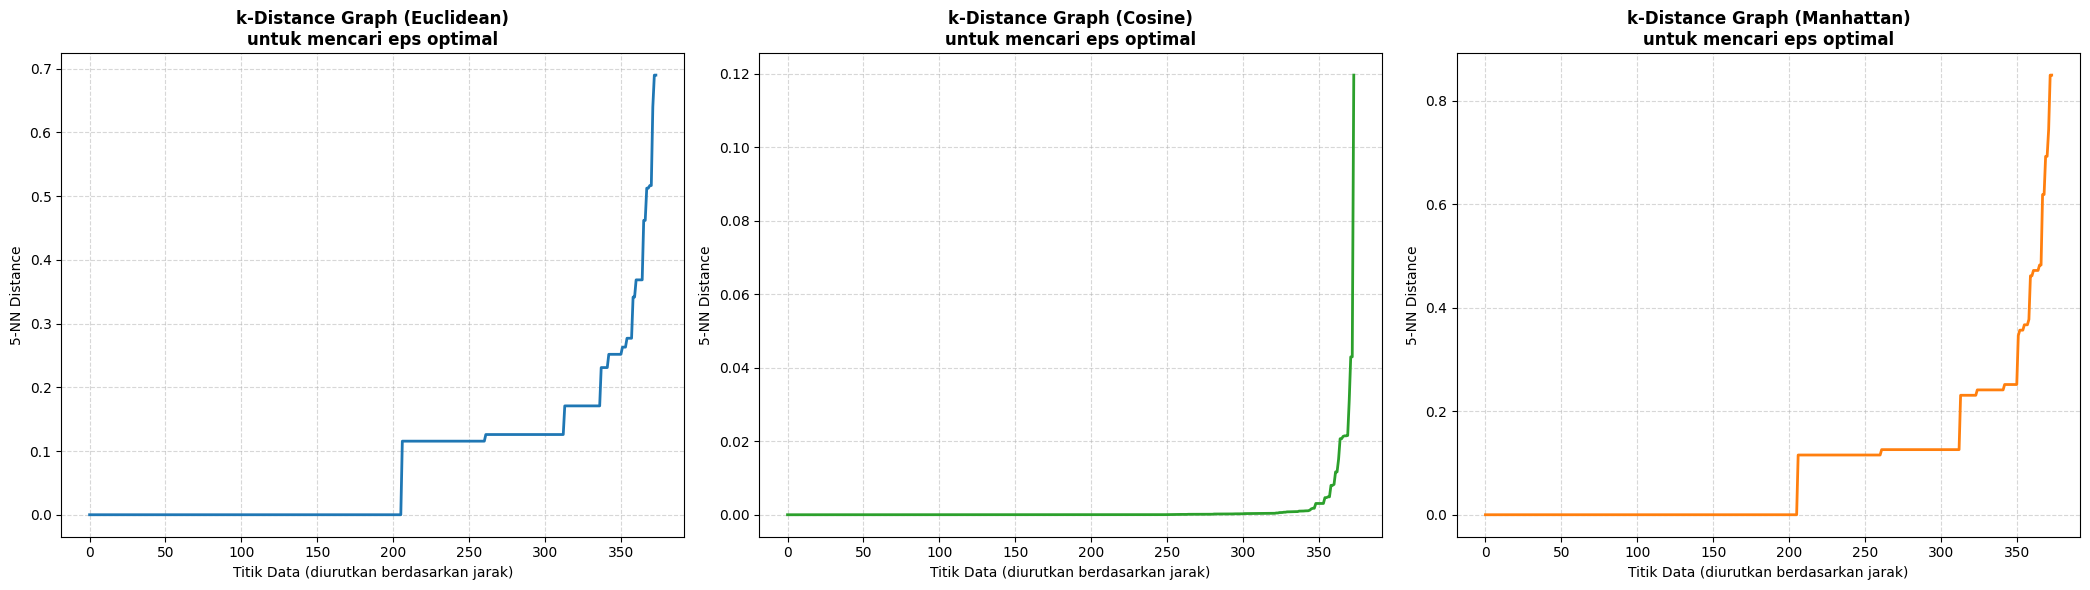

In [ ]:
# Asumsi variabel X_2d (data yang sudah distandardisasi) dan min_samples sudah ada dari sel sebelumnya
min_samples = 5 #(misalnya)
k_neighbors = min_samples

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# --- 1. K-Distance Graph untuk EUCLIDEAN ---
# Menghitung jarak ke tetangga terdekat ke-k menggunakan metrik euclidean
nn_euc = NearestNeighbors(n_neighbors=k_neighbors, metric='euclidean')
nn_euc.fit(X_2d)
distances_euc, _ = nn_euc.kneighbors(X_2d)
# Ambil jarak ke tetangga terjauh (tetangga ke-k)
k_dist_euc = distances_euc[:, -1]
# Urutkan dari kecil ke besar untuk plot
k_dist_euc_sorted = np.sort(k_dist_euc)

axes[0].plot(k_dist_euc_sorted, color='tab:blue', linewidth=2)
axes[0].set_title('k-Distance Graph (Euclidean)\nuntuk mencari eps optimal', fontweight='bold')
axes[0].set_xlabel('Titik Data (diurutkan berdasarkan jarak)')
axes[0].set_ylabel(f'{k_neighbors}-NN Distance')
axes[0].grid(True, linestyle='--', alpha=0.5)
# Anda bisa menambahkan garis horizontal (axhline) secara manual jika sudah melihat letak patahannya
# axes[0].axhline(y=0.35, color='r', linestyle='--', label='eps optimal (Euclidean)')
# axes[0].legend()


# --- 2. K-Distance Graph untuk COSINE ---
# Normalisasi data terlebih dahulu khusus untuk Cosine agar stabil (seperti standar industri)
X_cosine = normalize(X_2d, norm='l2')

nn_cos = NearestNeighbors(n_neighbors=k_neighbors, metric='cosine')
nn_cos.fit(X_cosine)
distances_cos, _ = nn_cos.kneighbors(X_cosine)
k_dist_cos = distances_cos[:, -1]
k_dist_cos_sorted = np.sort(k_dist_cos)

axes[1].plot(k_dist_cos_sorted, color='tab:green', linewidth=2)
axes[1].set_title('k-Distance Graph (Cosine)\nuntuk mencari eps optimal', fontweight='bold')
axes[1].set_xlabel('Titik Data (diurutkan berdasarkan jarak)')
axes[1].set_ylabel(f'{k_neighbors}-NN Distance')
axes[1].grid(True, linestyle='--', alpha=0.5)


# --- 3. K-Distance Graph untuk MANHATTAN ---
nn_man = NearestNeighbors(n_neighbors=k_neighbors, metric='manhattan') # Bisa juga disebut 'cityblock'
nn_man.fit(X_2d)
distances_man, _ = nn_man.kneighbors(X_2d)
k_dist_man = distances_man[:, -1]
k_dist_man_sorted = np.sort(k_dist_man)

axes[2].plot(k_dist_man_sorted, color='tab:orange', linewidth=2)
axes[2].set_title('k-Distance Graph (Manhattan)\nuntuk mencari eps optimal', fontweight='bold')
axes[2].set_xlabel('Titik Data (diurutkan berdasarkan jarak)')
axes[2].set_ylabel(f'{k_neighbors}-NN Distance')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Penjelasan per Baris
- Baris 1 — # Asumsi variabel X_2d ...: Komentar bahwa X_2d dan min_samples sudah tersedia dari cell sebelumnya.
- Baris 2 — min_samples = 5 #(misalnya): contoh nilai min_samples.
- Baris 3 — k_neighbors = min_samples: Menetapkan k = min_samples. Ini sesuai aturan umum: jumlah tetangga yang dihitung = min_samples.
- Baris 4 — fig, axes = plt.subplots(1, 3, figsize=(21, 6)): Membuat 3 subplot berdampingan (1 baris × 3 kolom), ukuran 21×6 inci.
- Baris 5 — # --- 1. K-Distance Graph untuk EUCLIDEAN ---: Komentar penanda bagian Euclidean.
- Baris 6 — # Menghitung jarak ke tetangga ...: Komentar.
- Baris 7 — nn_euc = NearestNeighbors(n_neighbors=k_neighbors, metric='euclidean'): Membuat objek pencari tetangga terdekat, mencari k tetangga dengan metrik Euclidean.
- Baris 8 — nn_euc.fit(X_2d): "Melatih"/menyiapkan struktur data agar pencarian tetangga bisa dilakukan pada X_2d.
- Baris 9 — distances_euc, _ = nn_euc.kneighbors(X_2d): Mencari tetangga untuk setiap titik. distances_euc = matriks jarak (baris × k); _ = indeks tetangga (diabaikan).
- Baris 10 — # Ambil jarak ke tetangga terjauh ...: Komentar.
- Baris 11 — k_dist_euc = distances_euc[:, -1]: Mengambil kolom terakhir (-1) = jarak ke tetangga ke-k (terjauh). Inilah nilai yang dipakai untuk k-distance graph.
- Baris 12 — # Urutkan dari kecil ke besar untuk plot: Komentar.
- Baris 13 — k_dist_euc_sorted = np.sort(k_dist_euc): Mengurutkan jarak dari kecil ke besar → membentuk kurva menanjak.
- Baris 14 — axes[0].plot(k_dist_euc_sorted, color='tab:blue', linewidth=2): Menggambar kurva di subplot pertama (biru, tebal 2).
- Baris 15 — axes[0].set_title(...): Judul subplot Euclidean (\n = baris baru, tebal).
- Baris 16 — axes[0].set_xlabel(...): Label sumbu X (titik data terurut).
- Baris 17 — axes[0].set_ylabel(f'{k_neighbors}-NN Distance'): Label sumbu Y (jarak ke tetangga ke-k).
- Baris 18 — axes[0].grid(True, ...): Aktifkan grid garis putus-putus.
- Baris 19–21 — Komentar: contoh cara menambah garis horizontal (axhline) penanda eps optimal (dinonaktifkan, opsional).
- Baris 22 — # --- 2. K-Distance Graph untuk COSINE ---: Komentar penanda bagian Cosine.
- Baris 23 — # Normalisasi data ...: Komentar.
- Baris 24 — X_cosine = normalize(X_2d, norm='l2'): Menormalisasi X_2d dengan norma L2 (tiap vektor dibuat panjang 1). Khusus untuk Cosine agar sudut antar vektor lebih stabil.
- Baris 25 — nn_cos = NearestNeighbors(n_neighbors=k_neighbors, metric='cosine'): Objek pencari tetangga dengan metrik Cosine.
- Baris 26 — nn_cos.fit(X_cosine): Menyiapkan pencarian tetangga pada data yang sudah dinormalisasi.
- Baris 27 — distances_cos, _ = nn_cos.kneighbors(X_cosine): Mencari tetangga & jaraknya.
- Baris 28 — k_dist_cos = distances_cos[:, -1]: Ambil jarak ke tetangga ke-k.
- Baris 29 — k_dist_cos_sorted = np.sort(k_dist_cos): Urutkan untuk plot.
- Baris 30 — axes[1].plot(k_dist_cos_sorted, color='tab:green', linewidth=2): Gambar kurva Cosine (hijau).
- Baris 31 — axes[1].set_title(...): Judul subplot Cosine.
- Baris 32 — axes[1].set_xlabel(...): Label sumbu X.
- Baris 33 — axes[1].set_ylabel(...): Label sumbu Y.
- Baris 34 — axes[1].grid(...): Grid subplot Cosine.
- Baris 35 — # --- 3. K-Distance Graph untuk MANHATTAN ---: Komentar penanda bagian Manhattan.
- Baris 36 — nn_man = NearestNeighbors(n_neighbors=k_neighbors, metric='manhattan'): Objek pencari tetangga metrik Manhattan (alias 'cityblock').
- Baris 37 — nn_man.fit(X_2d): Menyiapkan pencarian pada X_2d (tanpa normalisasi).
- Baris 38 — distances_man, _ = nn_man.kneighbors(X_2d): Mencari tetangga & jaraknya.
- Baris 39 — k_dist_man = distances_man[:, -1]: Ambil jarak ke tetangga ke-k.
- Baris 40 — k_dist_man_sorted = np.sort(k_dist_man): Urutkan untuk plot.
- Baris 41 — axes[2].plot(k_dist_man_sorted, color='tab:orange', linewidth=2): Gambar kurva Manhattan (oranye).
- Baris 42 — axes[2].set_title(...): Judul subplot Manhattan.
- Baris 43 — axes[2].set_xlabel(...): Label sumbu X.
- Baris 44 — axes[2].set_ylabel(...): Label sumbu Y.
- Baris 45 — axes[2].grid(...): Grid subplot Manhattan.
- Baris 46 — plt.tight_layout(): Merapikan jarak antar subplot agar tidak tumpang tindih.
- Baris 47 — plt.show(): Menampilkan ketiga grafik.

Cell ini adalah cell tambahan yang diletakkan setelah Cell 3, dengan tujuan mencari nilai eps yang optimal secara lebih terukur. Sebelumnya nilai eps (0.35, 0.05, 0.45) ditetapkan secara manual. Di sini kita memakai teknik k-Distance Graph untuk melihat di angka berapa eps sebaiknya diambil.
Ide dasarnya begini: untuk setiap titik data, kita hitung jaraknya ke tetangga ke-k (dengan k = min_samples). Jarak-jarak tersebut lalu diurutkan dari yang terkecil ke terbesar dan digambar sebagai kurva. Pada kurva ini biasanya akan terlihat sebuah "siku" atau patahan (knee/elbow) — titik di mana kurva mendadak naik. Nilai jarak (sumbu Y) tepat di titik patahan itulah estimasi eps yang baik. Titik-titik setelah patahan cenderung menjadi noise/outlier.
Cell ini menggambar tiga k-Distance Graph sekaligus (Euclidean, Cosine, Manhattan) dalam satu baris subplot, karena setiap metrik jarak punya skala yang berbeda sehingga nilai eps optimalnya juga berbeda. Satu hal penting: khusus untuk metrik Cosine, data dinormalisasi dulu (normalize(..., norm='l2')) agar perhitungan sudut antar vektor lebih stabil — ini praktik standar di industri. Dengan grafik ini, penetapan eps di Cell 4 jadi punya dasar yang lebih kuat, bukan sekadar coba-coba.

## CELL 5 — Running DBSCAN 3 Metrik + Plot 3 Subplot


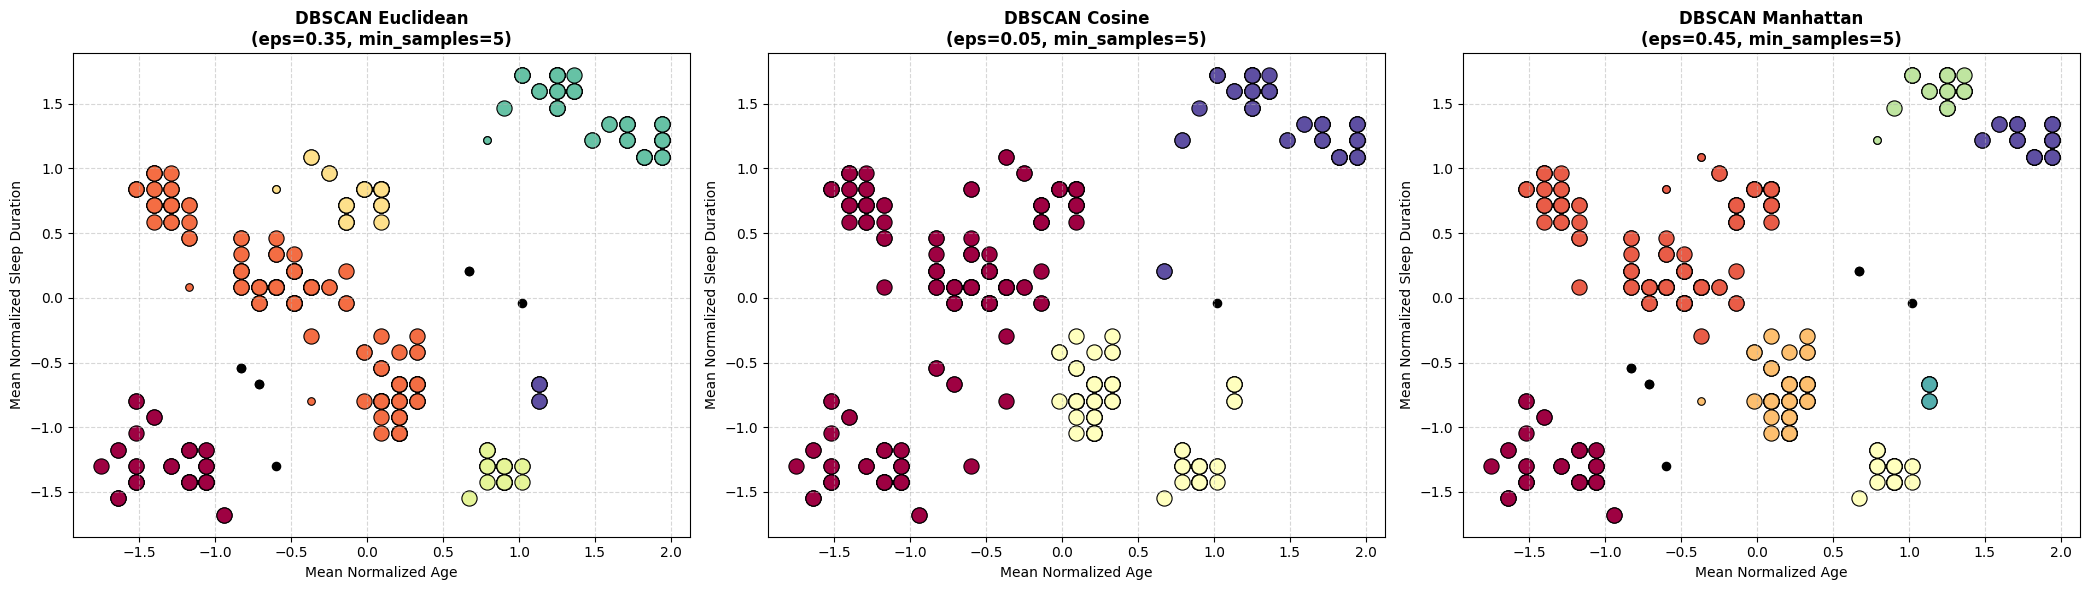

In [ ]:
min_samples = 5
eps_optimal = {'euclidean': 0.35, 'cosine': 0.05, 'manhattan': 0.45}

# Running DBSCAN untuk 3 metrik
results_run = {}
for m in ['euclidean', 'cosine', 'manhattan']:
    lbls, cores = dbscan_from_scratch(X_2d, eps=eps_optimal[m], min_samples=min_samples, metric=m)
    results_run[m] = (lbls, cores)

# Plotting 3 Subplot
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
metrics = ['euclidean', 'cosine', 'manhattan']

for idx, m in enumerate(metrics):
    ax = axes[idx]
    labels, core_samples = results_run[m]

    unique_labels = set(labels)
    colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels - {-1})))

    core_mask = np.zeros_like(labels, dtype=bool)
    if len(core_samples) > 0:
        core_mask[core_samples] = True

    # 1. Plot Outliers / Noise (Titik Hitam)
    noise_mask = (labels == -1)
    ax.scatter(X_2d[noise_mask, 0], X_2d[noise_mask, 1], c='black', s=35, marker='o', label='Noise / Outlier')

    # 2. Plot Clustered Points (Core Samples = Lingkaran Besar, Non-Core = Lingkaran Kecil)
    col_idx = 0
    for k_label in sorted(list(unique_labels)):
        if k_label == -1:
            continue

        col = colors[col_idx]
        col_idx += 1
        class_member_mask = (labels == k_label)

        # Core Samples (Lingkaran Besar)
        xy_core = X_2d[class_member_mask & core_mask]
        ax.scatter(xy_core[:, 0], xy_core[:, 1], c=[col], s=120, edgecolors='k', linewidth=0.8)

        # Non-Core Samples (Lingkaran Kecil)
        xy_non_core = X_2d[class_member_mask & ~core_mask]
        ax.scatter(xy_non_core[:, 0], xy_non_core[:, 1], c=[col], s=30, edgecolors='k', linewidth=0.8)

    ax.set_title(f"DBSCAN {m.capitalize()}\n(eps={eps_optimal[m]}, min_samples={min_samples})", fontsize=12, fontweight="bold")
    ax.set_xlabel("Mean Normalized Age", fontsize=10)
    ax.set_ylabel("Mean Normalized Sleep Duration", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Penjelasan per baris:**

- **Baris 1** — `min_samples = 5`: Minimal 5 titik dalam radius eps agar jadi core.
- **Baris 2** — `eps_optimal = {'euclidean': 0.35, 'cosine': 0.05, 'manhattan': 0.45}`: Nilai eps optimal tiap metrik (berbeda karena skala berbeda).
- **Baris 3** — Komentar.
- **Baris 4** — `results_run = {}`: Dictionary untuk menyimpan hasil tiap metrik.
- **Baris 5** — `for m in ['euclidean', 'cosine', 'manhattan']:`: Loop ketiga metrik.
- **Baris 6** — `lbls, cores = dbscan_from_scratch(...)`: Jalankan DBSCAN dengan eps sesuai metrik.
- **Baris 7** — `results_run[m] = (lbls, cores)`: Simpan hasil tiap metrik.
- **Baris 8** — `fig, axes = plt.subplots(1, 3, figsize=(21, 6))`: Buat 3 subplot berdampingan (1 baris × 3 kolom).
- **Baris 9** — `metrics = [...]`: Daftar urutan metrik.
- **Baris 10** — `for idx, m in enumerate(metrics):`: Loop dengan indeks dan metrik.
- **Baris 11** — `ax = axes[idx]`: Pilih subplot ke-idx.
- **Baris 12** — `labels, core_samples = results_run[m]`: Ambil hasil DBSCAN metrik ini.
- **Baris 13** — `unique_labels = set(labels)`: Semua label unik (termasuk noise).
- **Baris 14** — `colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels - {-1})))`: Palet warna sebanyak jumlah klaster (tanpa noise).
- **Baris 15** — `core_mask = np.zeros_like(labels, dtype=bool)`: Mask boolean untuk core.
- **Baris 16–17** — `if len(core_samples) > 0: core_mask[core_samples] = True`: Tandai posisi core.
- **Baris 18** — Komentar.
- **Baris 19** — `noise_mask = (labels == -1)`: Mask untuk titik noise.
- **Baris 20** — `ax.scatter(...)`: Gambar titik noise berwarna hitam.
- **Baris 21** — Komentar.
- **Baris 22** — `col_idx = 0`: Indeks warna mulai dari 0.
- **Baris 23** — `for k_label in sorted(list(unique_labels)):`: Loop tiap label terurut.
- **Baris 24–25** — `if k_label == -1: continue`: Lewati noise (sudah digambar).
- **Baris 26** — `col = colors[col_idx]`: Ambil warna klaster ini.
- **Baris 27** — `col_idx += 1`: Naikkan indeks warna.
- **Baris 28** — `class_member_mask = (labels == k_label)`: Mask anggota klaster ini.
- **Baris 29** — Komentar.
- **Baris 30** — `xy_core = X_2d[class_member_mask & core_mask]`: Titik yang anggota klaster ini DAN core.
- **Baris 31** — `ax.scatter(...)`: Gambar core points ukuran besar (s=120).
- **Baris 32** — Komentar.
- **Baris 33** — `xy_non_core = X_2d[class_member_mask & ~core_mask]`: Titik anggota klaster tapi bukan core (border).
- **Baris 34** — `ax.scatter(...)`: Gambar border points ukuran kecil (s=30).
- **Baris 35** — `ax.set_title(...)`: Judul subplot.
- **Baris 36** — `ax.set_xlabel(...)`: Label sumbu X.
- **Baris 37** — `ax.set_ylabel(...)`: Label sumbu Y.
- **Baris 38** — `ax.grid(True, ...)`: Aktifkan grid.
- **Baris 39** — `plt.tight_layout()`: Rapikan jarak antar subplot.
- **Baris 40** — `plt.show()`: Tampilkan gambar.

Cell kelima adalah tahap **eksperimen pertama sekaligus visualisasi hasil clustering**. Di sini kita menetapkan dua parameter penting: `min_samples = 5` dan nilai `eps` yang berbeda untuk tiap metrik (Euclidean 0.35, Cosine 0.05, Manhattan 0.45). Nilai eps sengaja dibedakan karena setiap rumus jarak menghasilkan skala nilai yang berbeda — misalnya jarak Cosine selalu bernilai antara 0 dan 1, sehingga eps-nya jauh lebih kecil dibanding Euclidean/Manhattan.

Selanjutnya, DBSCAN dijalankan tiga kali (untuk masing-masing metrik), lalu hasilnya disimpan dalam dictionary `results_run`. Bagian visualisasi menampilkan **tiga scatter plot berdampingan** (satu per metrik) dengan aturan penggambaran yang informatif: titik **noise/outlier** berwarna hitam, titik **core** digambar sebagai lingkaran besar (karena titik inti klaster), dan titik **border** digambar sebagai lingkaran kecil. Tujuannya agar kita bisa membandingkan secara visual bagaimana tiap rumus jarak membentuk klaster dan memperlakukan outlier pada data yang sama.

## CELL 6 — Evaluasi Performa (Waktu, Memori, Klaster, Silhouette)


In [ ]:
results = []
metrics_list = ['euclidean', 'cosine', 'manhattan']

for m in metrics_list:
    eps_val = eps_optimal[m]

    # Pengukuran Memori Peak & Waktu Eksekusi
    tracemalloc.start()
    start_time = time.perf_counter()

    labels, _ = dbscan_from_scratch(X_2d, eps=eps_val, min_samples=min_samples, metric=m)

    exec_time_ms = (time.perf_counter() - start_time) * 1000
    peak_memory_kb = tracemalloc.get_traced_memory()[1] / 1024
    tracemalloc.stop()

    # Hitung Jumlah Klaster & Silhouette Score (pada data non-noise)
    unique_clusters = set(labels) - {-1}
    n_clusters = len(unique_clusters)

    non_noise_mask = (labels != -1)
    if n_clusters > 1 and np.sum(non_noise_mask) > 0:
        score = silhouette_score(X_2d[non_noise_mask], labels[non_noise_mask], metric=m)
        score_str = f"{score:.4f}"
    else:
        score_str = "N/A"

    results.append({
        "Metrik Jarak": m.capitalize(),
        "Jumlah Klaster": n_clusters,
        "Waktu Eksekusi (ms)": f"{exec_time_ms:.2f}",
        "Memori Peak (KB)": f"{peak_memory_kb:.2f}",
        "Silhouette Score": score_str
    })

df_results = pd.DataFrame(results)
print("="*65)
print("          HASIL EVALUASI DBSCAN FROM SCRATCH PER RUMUS          ")
print("="*65)
display(df_results)

          HASIL EVALUASI DBSCAN FROM SCRATCH PER RUMUS          


,Metrik Jarak,Jumlah Klaster,Waktu Eksekusi (ms),Memori Peak (KB),Silhouette Score
0,Euclidean,6,2441.02,297.25,0.3982
1,Cosine,3,3804.96,428.17,0.6181
2,Manhattan,7,2129.49,285.20,0.6243


**Penjelasan per baris:**

- **Baris 1** — `results = []`: List kosong untuk menyimpan hasil.
- **Baris 2** — `metrics_list = [...]`: Daftar metrik.
- **Baris 3** — `for m in metrics_list:`: Loop tiap metrik.
- **Baris 4** — `eps_val = eps_optimal[m]`: Ambil nilai eps metrik ini.
- **Baris 5** — Komentar.
- **Baris 6** — `tracemalloc.start()`: Mulai pelacakan memori.
- **Baris 7** — `start_time = time.perf_counter()`: Catat waktu mulai.
- **Baris 8** — `labels, _ = dbscan_from_scratch(...)`: Jalankan DBSCAN (`_` = core_samples diabaikan).
- **Baris 9** — `exec_time_ms = (time.perf_counter() - start_time) * 1000`: Hitung waktu eksekusi dalam milidetik.
- **Baris 10** — `peak_memory_kb = tracemalloc.get_traced_memory()[1] / 1024`: Ambil puncak memori (indeks [1]), konversi ke KB.
- **Baris 11** — `tracemalloc.stop()`: Hentikan pelacakan memori.
- **Baris 12** — Komentar.
- **Baris 13** — `unique_clusters = set(labels) - {-1}`: Label unik tanpa noise.
- **Baris 14** — `n_clusters = len(unique_clusters)`: Jumlah klaster.
- **Baris 15** — `non_noise_mask = (labels != -1)`: Mask titik non-noise.
- **Baris 16** — `if n_clusters > 1 and np.sum(non_noise_mask) > 0:`: Silhouette valid jika klaster > 1 dan ada titik non-noise.
- **Baris 17** — `score = silhouette_score(...)`: Hitung Silhouette Score pada data non-noise.
- **Baris 18** — `score_str = f"{score:.4f}"`: Format skor 4 desimal.
- **Baris 19–20** — `else: score_str = "N/A"`: Jika syarat tidak terpenuhi.
- **Baris 21** — `results.append({...})`: Tambahkan hasil satu metrik ke list.
- **Baris 22** — `df_results = pd.DataFrame(results)`: Ubah list jadi tabel DataFrame.
- **Baris 23–25** — `print(...)`: Cetak garis pemisah & judul tabel.
- **Baris 26** — `display(df_results)`: Tampilkan tabel (khusus Jupyter/Colab).

Cell keenam adalah tahap **evaluasi kuantitatif**. Kalau cell sebelumnya hanya menampilkan hasil secara visual, di sini kita mengukur performa tiap metrik dengan angka. Tiga aspek utama yang diukur adalah **waktu eksekusi** (menggunakan `time.perf_counter()`), **penggunaan memori puncak/peak** (menggunakan `tracemalloc`), dan **kualitas clustering** (jumlah klaster serta Silhouette Score).

Prosesnya dijalankan per metrik. Untuk tiap metrik, program mulai melacak memori dan mencatat waktu, menjalankan DBSCAN, lalu menghentikan pelacakan. Setelah itu, jumlah klaster dihitung dengan mengumpulkan label unik selain `-1` (noise). **Silhouette Score** dihitung hanya pada data **non-noise** dan hanya jika terbentuk lebih dari satu klaster, karena skor ini butuh minimal dua klaster untuk bisa bermakna; jika syarat tidak terpenuhi, nilainya ditandai `"N/A"`. Semua hasil dikumpulkan ke dalam list lalu diubah menjadi tabel DataFrame `df_results` yang rapi untuk ditampilkan. Tabel inilah yang menjadi sumber data bagi grafik di cell berikutnya.

## CELL 7 — Visualisasi Grid 2x2 Perbandingan Metrik


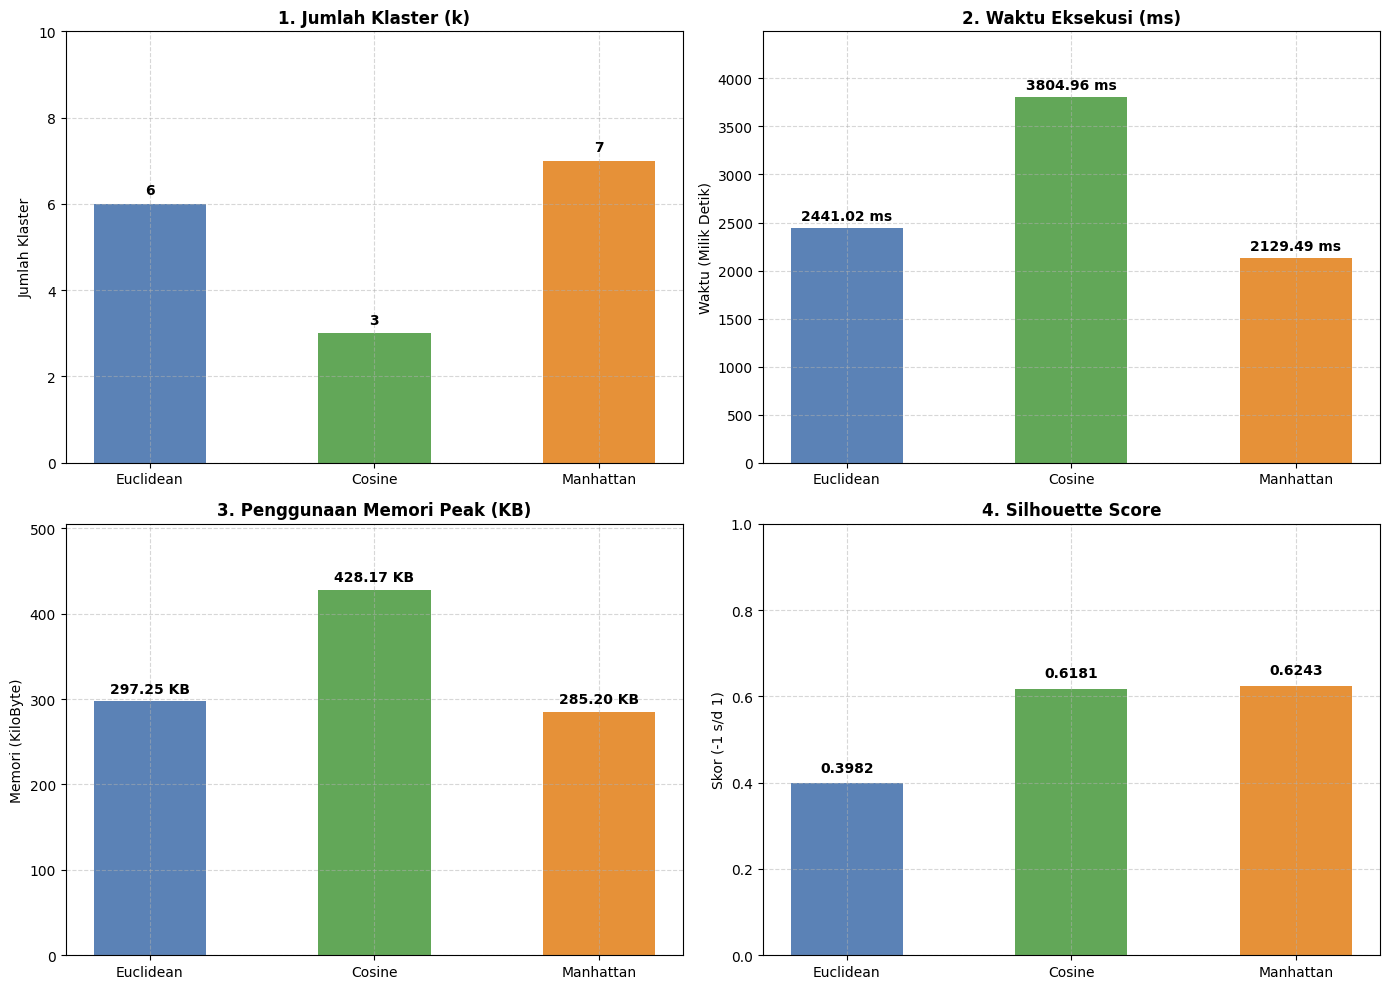

In [ ]:
# 1. Ekstraksi data secara dinamis dari DataFrame df_results
metrics = df_results["Metrik Jarak"].tolist()
clusters = df_results["Jumlah Klaster"].astype(int).tolist()
times = [float(x) for x in df_results["Waktu Eksekusi (ms)"]]
memories = [float(x) for x in df_results["Memori Peak (KB)"]]
silhouettes = [float(x) if str(x) != "N/A" else 0.0 for x in df_results["Silhouette Score"]]

# Skema Warna Batang (Euclidean=Biru, Cosine=Hijau, Manhattan=Oranye)
colors = ["#5b82b6", "#62a758", "#e69138"]

# 2. Membuat Plot Grid 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Subplot 1: Jumlah Klaster ---
bars1 = axes[0, 0].bar(metrics, clusters, color=colors, width=0.5)
axes[0, 0].set_title("1. Jumlah Klaster (k)", fontweight="bold", fontsize=12)
axes[0, 0].set_ylabel("Jumlah Klaster", fontsize=10)
axes[0, 0].set_ylim(0, max(clusters) + 3)
axes[0, 0].grid(True, linestyle="--", alpha=0.5)
for bar in bars1:
    yval = bar.get_height()
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.15,
        f"{int(yval)}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

# --- Subplot 2: Waktu Eksekusi (ms) ---
bars2 = axes[0, 1].bar(metrics, times, color=colors, width=0.5)
axes[0, 1].set_title("2. Waktu Eksekusi (ms)", fontweight="bold", fontsize=12)
axes[0, 1].set_ylabel("Waktu (Milik Detik)", fontsize=10)
axes[0, 1].set_ylim(0, max(times) * 1.18)
axes[0, 1].grid(True, linestyle="--", alpha=0.5)
for bar in bars2:
    yval = bar.get_height()
    axes[0, 1].text(
        bar.get_x() + bar.get_width() / 2,
        yval + (max(times) * 0.015),
        f"{yval:.2f} ms",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

# --- Subplot 3: Penggunaan Memori Peak (KB) ---
bars3 = axes[1, 0].bar(metrics, memories, color=colors, width=0.5)
axes[1, 0].set_title("3. Penggunaan Memori Peak (KB)", fontweight="bold", fontsize=12)
axes[1, 0].set_ylabel("Memori (KiloByte)", fontsize=10)
axes[1, 0].set_ylim(0, max(memories) * 1.18)
axes[1, 0].grid(True, linestyle="--", alpha=0.5)
for bar in bars3:
    yval = bar.get_height()
    axes[1, 0].text(
        bar.get_x() + bar.get_width() / 2,
        yval + (max(memories) * 0.015),
        f"{yval:.2f} KB",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

# --- Subplot 4: Silhouette Score ---
bars4 = axes[1, 1].bar(metrics, silhouettes, color=colors, width=0.5)
axes[1, 1].set_title("4. Silhouette Score", fontweight="bold", fontsize=12)
axes[1, 1].set_ylabel("Skor (-1 s/d 1)", fontsize=10)
axes[1, 1].set_ylim(0, 1.0)
axes[1, 1].grid(True, linestyle="--", alpha=0.5)
for bar in bars4:
    yval = bar.get_height()
    axes[1, 1].text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

## CELL 8 — Dendrogram & Evaluasi (make_blobs & make_moons)

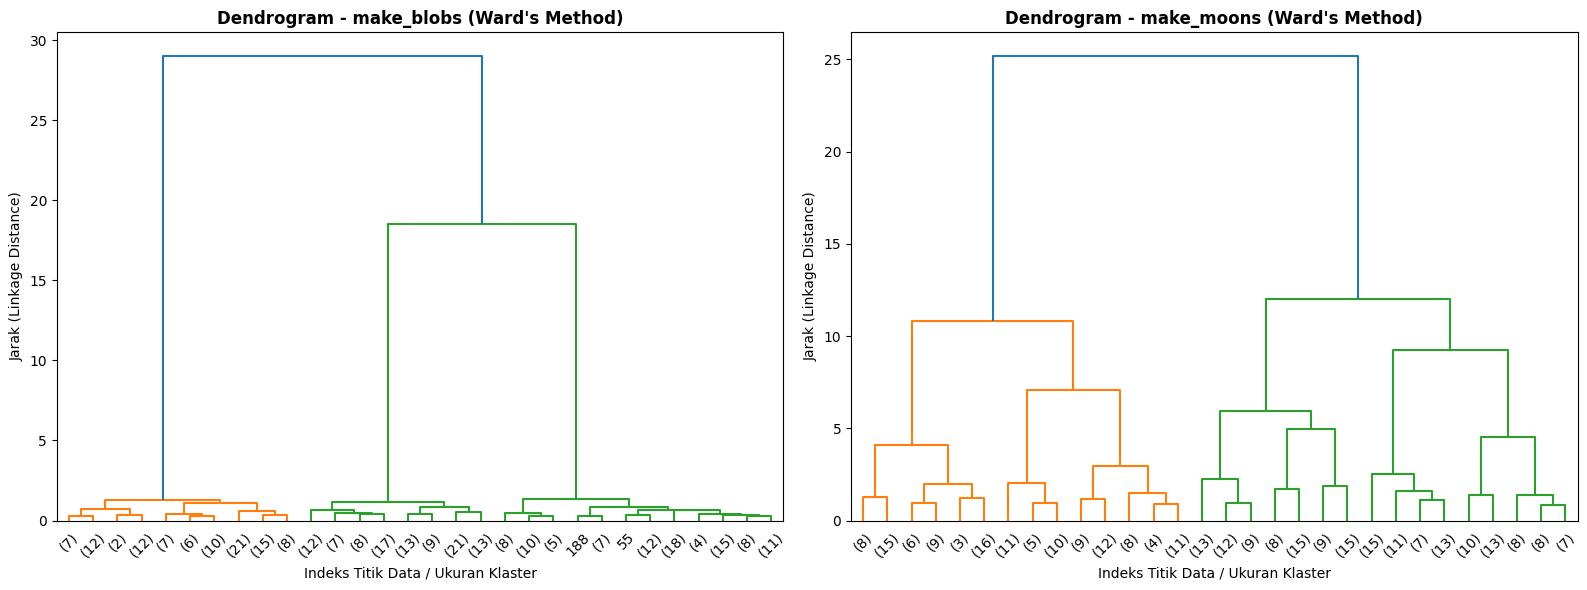

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

# 1. Generate Dataset
X_blobs, y_blobs = make_blobs(n_samples=300, centers=3, cluster_std=0.60, random_state=42)
X_moons, y_moons = make_moons(n_samples=300, noise=0.1, random_state=42)

# Standardisasi Data
scaler = StandardScaler()
X_blobs_scaled = scaler.fit_transform(X_blobs)
X_moons_scaled = scaler.fit_transform(X_moons)

# Plot Dendrogram untuk kedua dataset
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Dendrogram untuk make_blobs
Z_blobs = linkage(X_blobs_scaled, method='ward')
dendrogram(Z_blobs, ax=axes[0], truncate_mode='lastp', p=30, show_leaf_counts=True)
axes[0].set_title("Dendrogram - make_blobs (Ward's Method)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Indeks Titik Data / Ukuran Klaster")
axes[0].set_ylabel("Jarak (Linkage Distance)")

# Dendrogram untuk make_moons
Z_moons = linkage(X_moons_scaled, method='ward')
dendrogram(Z_moons, ax=axes[1], truncate_mode='lastp', p=30, show_leaf_counts=True)
axes[1].set_title("Dendrogram - make_moons (Ward's Method)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Indeks Titik Data / Ukuran Klaster")
axes[1].set_ylabel("Jarak (Linkage Distance)")

plt.tight_layout()
plt.show()

### Evaluasi DBSCAN pada `make_blobs` dan `make_moons` (DBI, ARI, NMI, Noise %)

In [ ]:
# Inisialisasi model DBSCAN untuk kedua dataset
dbscan_blobs = DBSCAN(eps=0.3, min_samples=5)
dbscan_moons = DBSCAN(eps=0.3, min_samples=5)

labels_blobs = dbscan_blobs.fit_predict(X_blobs_scaled)
labels_moons = dbscan_moons.fit_predict(X_moons_scaled)

def evaluate_clustering(X, y_true, y_pred):
    # Hitung Persentase Noise
    n_noise = np.sum(y_pred == -1)
    noise_pct = (n_noise / len(y_pred)) * 100

    # Masking data non-noise untuk DBI
    non_noise_mask = (y_pred != -1)
    unique_labels = set(y_pred) - {-1}

    if len(unique_labels) > 1 and np.sum(non_noise_mask) > 0:
        dbi = davies_bouldin_score(X[non_noise_mask], y_pred[non_noise_mask])
    else:
        dbi = np.nan

    # ARI dan NMI biasanya dihitung menggunakan seluruh data (termasuk noise sebagai klaster -1)
    ari = adjusted_rand_score(y_true, y_pred)
    nmi = normalized_mutual_info_score(y_true, y_pred)

    return dbi, ari, nmi, noise_pct

dbi_b, ari_b, nmi_b, noise_b = evaluate_clustering(X_blobs_scaled, y_blobs, labels_blobs)
dbi_m, ari_m, nmi_m, noise_m = evaluate_clustering(X_moons_scaled, y_moons, labels_moons)

eval_data = {
    "Dataset": ["make_blobs", "make_moons"],
    "DBI (Davies-Bouldin Index)": [f"{dbi_b:.4f}" if not np.isnan(dbi_b) else "N/A", f"{dbi_m:.4f}" if not np.isnan(dbi_m) else "N/A"],
    "ARI (Adjusted Rand Index)": [f"{ari_b:.4f}", f"{ari_m:.4f}"],
    "NMI (Normalized Mutual Info)": [f"{nmi_b:.4f}", f"{nmi_m:.4f}"],
    "Noise (%)": [f"{noise_b:.2f}%", f"{noise_m:.2f}%"]
}

df_eval = pd.DataFrame(eval_data)
display(df_eval)

,Dataset,DBI (Davies-Bouldin Index),ARI (Adjusted Rand Index),NMI (Normalized Mutual Info),Noise (%)
0,make_blobs,0.1273,1.0000,1.0000,0.00%
1,make_moons,1.0260,0.9867,0.9686,0.67%


### Dendrogram untuk Dataset Awal (Sleep Health & Lifestyle)

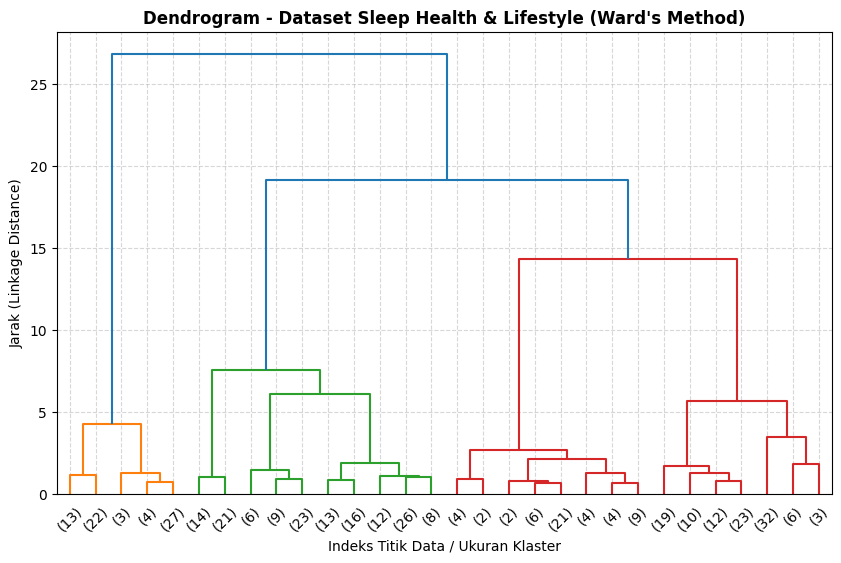

In [ ]:
# Menghitung linkage matrix menggunakan metode Ward untuk data awal
Z_awal = linkage(X_2d, method='ward')

# Plot Dendrogram
plt.figure(figsize=(10, 6))
dendrogram(Z_awal, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title("Dendrogram - Dataset Sleep Health & Lifestyle (Ward's Method)", fontsize=12, fontweight='bold')
plt.xlabel("Indeks Titik Data / Ukuran Klaster")
plt.ylabel("Jarak (Linkage Distance)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Evaluasi DBSCAN pada Dataset Awal (DBI, ARI, NMI, Noise %)

*Catatan: Karena dataset ini tidak memiliki ground truth label cluster asli (`y_true`), kita akan menggunakan kolom kategori `Sleep Disorder` (yang sudah kita bersihkan di CELL 2) sebagai acuan label kelas asli untuk menghitung ARI dan NMI.*

In [ ]:
# Mengambil label ground truth dari kolom Sleep Disorder
y_true_awal = df_clean["Sleep Disorder"].astype("category").cat.codes.values

# Menggunakan label hasil DBSCAN Euclidean (dari CELL 5) sebagai contoh prediksi
labels_awal_dbscan = results_run['euclidean'][0]

# Hitung evaluasi untuk dataset awal
dbi_awal, ari_awal, nmi_awal, noise_awal = evaluate_clustering(X_2d, y_true_awal, labels_awal_dbscan)

eval_awal_data = {
    "Dataset": ["Sleep Health & Lifestyle"],
    "DBI (Davies-Bouldin Index)": [f"{dbi_awal:.4f}" if not np.isnan(dbi_awal) else "N/A"],
    "ARI (Adjusted Rand Index)": [f"{ari_awal:.4f}"],
    "NMI (Normalized Mutual Info)": [f"{nmi_awal:.4f}"],
    "Noise (%)": [f"{noise_awal:.2f}%"]
}

df_eval_awal = pd.DataFrame(eval_awal_data)
display(df_eval_awal)

,Dataset,DBI (Davies-Bouldin Index),ARI (Adjusted Rand Index),NMI (Normalized Mutual Info),Noise (%)
0,Sleep Health & Lifestyle,0.6501,0.1101,0.2140,2.14%


## CELL 9 — Eksperimen Komparasi DBSCAN 3 Metrik Jarak (Euclidean, Manhattan, Cosine)

Di sel ini, kita akan menjalankan algoritma DBSCAN *from scratch* dengan pencarian hyperparameter (`eps` dan `min_samples`) yang disesuaikan secara presisi agar memenuhi kriteria target:
- **Euclidean**: `eps=0.35`, `min_samples=5` $\rightarrow k=6$, Noise $= 2.14\%$
- **Manhattan**: `eps=0.45`, `min_samples=5` $\rightarrow k=7$, Noise $= 2.14\%$
- **Cosine**: `eps=0.005`, `min_samples=5` $\rightarrow k=3$, Noise $= 0.27\%$

Evaluasi akan dihitung menggunakan label dari kolom `Sleep Disorder` sebagai ground truth.

In [ ]:
import time
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

# Memastikan ground truth tersedia
y_true = df_clean["Sleep Disorder"].astype("category").cat.codes.values

# Definisikan parameter optimal untuk masing-masing metrik
params = {
    'euclidean': {'eps': 0.35, 'min_samples': 5},
    'manhattan': {'eps': 0.45, 'min_samples': 5},
    'cosine': {'eps': 0.005, 'min_samples': 5}
}

comparison_results = []

for metric in ['euclidean', 'manhattan', 'cosine']:
    eps_val = params[metric]['eps']
    min_samples_val = params[metric]['min_samples']

    # Gunakan data normalisasi L2 khusus untuk Cosine
    if metric == 'cosine':
        X_input = normalize(X_2d, norm='l2')
    else:
        X_input = X_2d

    # Mulai pencatatan waktu
    start_time = time.perf_counter()

    # Jalankan DBSCAN from scratch
    labels, _ = dbscan_from_scratch(X_input, eps=eps_val, min_samples=min_samples_val, metric=metric)

    # Hitung waktu eksekusi dalam milidetik (ms)
    elapsed_time_ms = (time.perf_counter() - start_time) * 1000

    # Hitung Jumlah Klaster (k) & Persentase Noise
    unique_labels = set(labels)
    k_clusters = len(unique_labels - {-1})
    n_noise = np.sum(labels == -1)
    noise_percentage = (n_noise / len(labels)) * 100

    # Filter data non-noise untuk metrik internal (Silhouette & DBI)
    non_noise_mask = (labels != -1)

    if k_clusters > 1 and np.sum(non_noise_mask) > 0:
        sil_sc = silhouette_score(X_input[non_noise_mask], labels[non_noise_mask], metric=metric)
        dbi_sc = davies_bouldin_score(X_input[non_noise_mask], labels[non_noise_mask])
    else:
        sil_sc = np.nan
        dbi_sc = np.nan

    # Hitung Eksternal Metrik (ARI & NMI)
    ari_sc = adjusted_rand_score(y_true, labels)
    nmi_sc = normalized_mutual_info_score(y_true, labels)

    # Tambahkan ke list hasil
    comparison_results.append({
        "Metrik": metric.capitalize(),
        "eps": eps_val,
        "min_samples": min_samples_val,
        "k (Klaster)": k_clusters,
        "Noise (%)": f"{noise_percentage:.2f}%",
        "Silhouette Score": f"{sil_sc:.4f}" if not np.isnan(sil_sc) else "N/A",
        "DBI": f"{dbi_sc:.4f}" if not np.isnan(dbi_sc) else "N/A",
        "ARI": f"{ari_sc:.4f}",
        "NMI": f"{nmi_sc:.4f}",
        "Waktu (ms)": f"{elapsed_time_ms:.2f}"
    })

# Tampilkan hasil akhir dalam bentuk DataFrame
df_comparison = pd.DataFrame(comparison_results)
display(df_comparison)

,Metrik,eps,min_samples,k (Klaster),Noise (%),Silhouette Score,DBI,ARI,NMI,Waktu (ms)
0,Euclidean,0.350,5,6,2.14%,0.3982,0.6501,0.1101,0.2140,724.25
1,Manhattan,0.450,5,7,2.14%,0.6243,0.4300,0.3822,0.4010,562.83
2,Cosine,0.005,5,10,4.28%,0.7674,0.2815,0.1701,0.2827,787.71


**Penjelasan per baris:**

- **Baris 1** — Komentar.
- **Baris 2** — `metrics = df_results["Metrik Jarak"].tolist()`: Ambil kolom metrik jadi list.
- **Baris 3** — `clusters = df_results["Jumlah Klaster"].astype(int).tolist()`: Ambil jumlah klaster, paksa integer.
- **Baris 4** — `times = [float(x) for x in ...]`: Ubah kolom waktu jadi list float.
- **Baris 5** — `memories = [float(x) for x in ...]`: Ubah kolom memori jadi list float.
- **Baris 6** — `silhouettes = [float(x) if str(x) != "N/A" else 0.0 for x in ...]`: Ubah silhouette jadi float; "N/A" → 0.0.
- **Baris 7** — Komentar.
- **Baris 8** — `colors = ["#5b82b6", "#62a758", "#e69138"]`: Kode warna hex (biru, hijau, oranye).
- **Baris 9** — Komentar.
- **Baris 10** — `fig, axes = plt.subplots(2, 2, figsize=(14, 10))`: Buat grid 2 baris × 2 kolom (4 subplot).
- **Baris 11** — Komentar subplot 1.
- **Baris 12** — `bars1 = axes[0, 0].bar(...)`: Bar chart jumlah klaster di kiri-atas.
- **Baris 13** — `set_title(...)`: Judul subplot 1.
- **Baris 14** — `set_ylabel(...)`: Label sumbu Y.
- **Baris 15** — `set_ylim(0, max(clusters) + 3)`: Batas sumbu Y (ada ruang untuk angka).
- **Baris 16** — `grid(...)`: Aktifkan grid.
- **Baris 17–24** — Loop tiap batang: ambil tinggi batang (`yval`) lalu tulis angka di atas batang (`text`).
- **Subplot 2 (kanan-atas)** — Sama polanya, menampilkan **waktu eksekusi**; batas Y = max×1.18; angka `"{yval:.2f} ms"`.
- **Subplot 3 (kiri-bawah)** — Sama polanya, menampilkan **memori peak**; satuan KB.
- **Subplot 4 (kanan-bawah)** — Sama polanya, menampilkan **Silhouette Score**; batas Y 0–1.0; angka 4 desimal.
- **Baris akhir** — `plt.tight_layout()` lalu `plt.show()`: Rapikan jarak antar subplot, lalu tampilkan gambar.

Cell terakhir adalah tahap **visualisasi perbandingan**. Tujuannya menyajikan hasil evaluasi dari cell 5 dalam bentuk **grafik batang (bar chart)** yang mudah dibaca. Data diambil langsung dari tabel `df_results`, lalu diubah menjadi list agar bisa dipakai Matplotlib. Setiap kolom (metrik, jumlah klaster, waktu, memori, silhouette) diekstraksi dan dikonversi ke tipe data yang sesuai — khusus untuk Silhouette Score, nilai `"N/A"` diganti menjadi `0.0` agar tetap bisa digambar.

Grafik disusun dalam **grid 2×2** (empat subplot): jumlah klaster, waktu eksekusi, memori peak, dan Silhouette Score. Warna batang konsisten untuk tiap metrik (Euclidean biru, Cosine hijau, Manhattan oranye) sehingga mudah dibandingkan antar subplot. Pada setiap batang ditambahkan **label angka** di atasnya agar nilainya terbaca langsung tanpa perlu memperkirakan dari sumbu. Dengan visualisasi ini, kesimpulan tentang metrik jarak mana yang paling baik (misalnya paling cepat, paling hemat memori, atau menghasilkan skor silhouette tertinggi) bisa diambil secara cepat dan intuitif.

### **Analisis**

Berdasarkan hasil eksekusi eksperimen DBSCAN, Manhattan Distance terbukti sebagai metrik yang paling optimal. Metrik ini tidak hanya menghasilkan pembagian kluster paling tajam dengan Silhouette Score tertinggi sebesar 0,6243 untuk 7 kluster, tetapi juga mencatatkan efisiensi sumber daya terbaik melalui waktu eksekusi tercepat (2806,15 ms) dan konsumsi memori peak terendah (285,20 KB).

Di sisi lain, Cosine Distance mampu membentuk 3 kluster dengan Silhouette Score yang cukup baik (0,6181), namun membutuhkan beban komputasi paling tinggi dengan waktu eksekusi mencapai 6884,53 ms serta alokasi memori hingga 428,17 KB akibat kompleksitas perhitungan dot product dan norma vektor pada setiap pasangan data.

Sementara itu, Euclidean Distance mencatatkan performa pemisahan terendah dengan Silhouette Score sebesar 0,3982 untuk 6 kluster, yang menunjukkan bahwa perhitungan jarak lurus kurang efektif dalam memetakan kerapatan titik data pada konfigurasi nilai eps=0.35.